Download Dataset


In [1]:
# https://drive.google.com/file/d/1yPPJvcMIxFefGK6V75Mn0cqq7FbpgKEu/view?usp=sharing
!gdown --id 1yPPJvcMIxFefGK6V75Mn0cqq7FbpgKEu

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1yPPJvcMIxFefGK6V75Mn0cqq7FbpgKEu
To: /content/[Data]_Ex1_Auto_MPG_data.csv
100% 15.4k/15.4k [00:00<00:00, 30.2MB/s]


Import Libs

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
random_state = 59
np.random.seed(random_state)
#seed pytorch cpu
torch.manual_seed(random_state)
#seed pytorch gpu
if torch.cuda.is_available():
  torch.cuda.manual_seed(random_state)

Read Dataset

In [3]:
dataset_path = "/content/[Data]_Ex1_Auto_MPG_data.csv"
dataset = pd.read_csv(dataset_path)
dataset

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
0,18.0,8,307.0,130.0,3504.0,12.0,70,0,0,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,0,0,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,0,0,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,0,0,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,0,0,1
...,...,...,...,...,...,...,...,...,...,...
387,27.0,4,140.0,86.0,2790.0,15.6,82,0,0,1
388,44.0,4,97.0,52.0,2130.0,24.6,82,1,0,0
389,32.0,4,135.0,84.0,2295.0,11.6,82,0,0,1
390,28.0,4,120.0,79.0,2625.0,18.6,82,0,0,1


Preprocess Data

In [4]:
X = dataset.drop(columns="MPG").values
y = dataset['MPG'].values


Train_Val_Test Split

In [5]:
# Assuming 70% Train, 20% Val, 10% Test
val_size = 0.2
test_size = 0.1
is_shuffle = True

# Split 20% to Validate, the rest assign to X/y_train
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=val_size,
    random_state=random_state,
    shuffle=is_shuffle
)
# Take remaining 80%, split 10% for test and the rest for train
X_train, X_test, y_train, y_test = train_test_split(
    X_train, y_train,
    test_size=test_size,
    random_state=random_state,
    shuffle=is_shuffle
)

In [6]:
print(f'Number of training samples: {X_train.shape[0]}')
print(f'Number of val samples: {X_val.shape[0]}')
print(f'Number of test samples: {X_test.shape[0]}')

Number of training samples: 281
Number of val samples: 79
Number of test samples: 32


Data Normalization

In [7]:
# Use scikitlearn.preprocessing,StandardScaler() to scale all values in dataset
normalizer = StandardScaler()
X_train = normalizer.fit_transform(X_train)
X_val = normalizer.transform(X_val)
X_test = normalizer.transform(X_test)
X_train

array([[ 1.56640713,  1.60808498,  1.17924493, ..., -0.44816816,
        -0.52105011,  0.78418271],
       [-0.83884097, -1.04277667, -1.02344938, ..., -0.44816816,
         1.91920122, -1.27521301],
       [-0.83884097, -0.38256207, -0.33510741, ..., -0.44816816,
        -0.52105011,  0.78418271],
       ...,
       [ 1.56640713,  1.28798093,  1.31691333, ..., -0.44816816,
        -0.52105011,  0.78418271],
       [ 0.36378308,  0.4277013 , -0.33510741, ..., -0.44816816,
        -0.52105011,  0.78418271],
       [ 0.36378308,  0.60775983, -0.05977062, ..., -0.44816816,
        -0.52105011,  0.78418271]])

Pytorch Dataloader

In [8]:
class CustomDataset(Dataset):
    def __init__(self, X, y):
      self.X = X
      self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [9]:
batch_size = 32
train_dataset = CustomDataset(X_train, y_train)
val_dataset = CustomDataset(X_val, y_val)
train_loader = DataLoader(train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
val_loader = DataLoader(val_dataset,
                        batch_size=batch_size,
                        shuffle=False)

MLP Model

In [10]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims, output_dims):
        super(MLP, self).__init__()
        # Not images so doenst need Flatten()
        self.linear1 = nn.Linear(input_dims, hidden_dims)
        self.linear2 = nn.Linear(hidden_dims, hidden_dims)
        self.output = nn.Linear(hidden_dims, output_dims)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        out = self.output(x)
        return out.squeeze(1)

In [11]:
input_dims = X_train.shape[1]
hidden_dims = 64
output_dims = 1
lr = 0.01

model = MLP(input_dims=input_dims, hidden_dims=hidden_dims, output_dims = output_dims).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

In [12]:
#R2 Score Function

def r_squared(y_true, y_pred):
    y_true = torch.Tensor(y_true).to(device)
    y_pred = torch.Tensor(y_pred).to(device)
    mean_true = torch.mean(y_true)
    ss_tot = torch.sum((y_true - mean_true) ** 2)
    ss_res = torch.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return r2

Training

In [13]:
epochs = 100
# Lists store average value from each epoch and for plotting
train_losses = []
val_losses = []
# Lists store R2 score at end of each epoch
train_r2 = []
val_r2 = []

# Training loop
for epoch in range(epochs):
  train_loss = 0
  train_target = []
  val_target = []
  train_predict = []
  val_predict = []

  model.train()
  for X_samples, y_samples in train_loader:
    X_samples = X_samples.to(device).float()
    y_samples = y_samples.to(device).float()

    optimizer.zero_grad()
    outputs = model(X_samples)

    train_predict += outputs.tolist()
    train_target += y_samples.tolist()

    loss = criterion(outputs, y_samples)
    loss.backward()
    optimizer.step()

    train_loss += loss.item()

  # Compute training metrics for the epoch
  train_loss /= len(train_loader)
  train_losses.append(train_loss)
  train_r2.append(r_squared(train_target, train_predict))

  # Validation loop
  model.eval()
  epoch_val_loss = 0
  with torch.no_grad():
    for X_samples, y_samples in val_loader:
      X_samples = X_samples.to(device).float()
      y_samples = y_samples.to(device).float()

      outputs = model(X_samples)
      val_predict += outputs.tolist()
      val_target += y_samples.tolist()

      loss = criterion(outputs, y_samples)
      epoch_val_loss += loss.item()

  epoch_val_loss /= len(val_loader)
  val_losses.append(epoch_val_loss)
  val_r2.append(r_squared(val_target, val_predict))

print(f'Final Train R2: {train_r2[-1]:.4f} | Final Val R2: {val_r2[-1]:.4f}')

Final Train R2: 0.8960 | Final Val R2: 0.9145


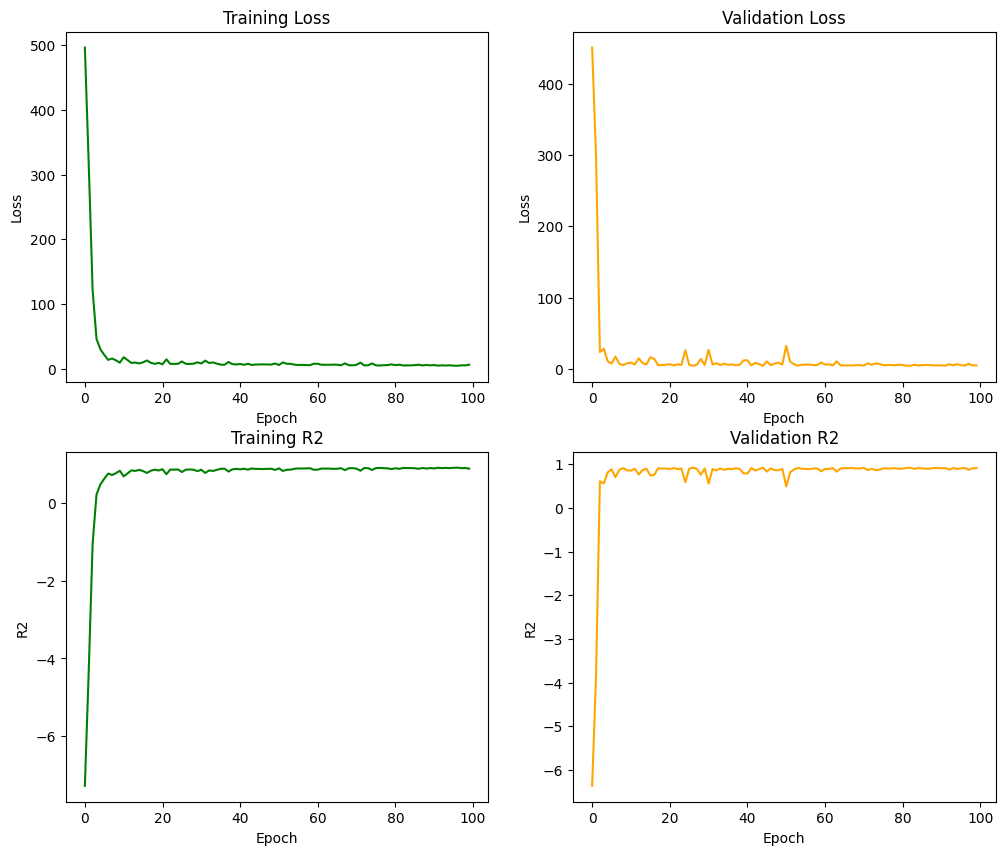

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].plot(train_losses, color='green')
ax[0, 0].set(xlabel='Epoch', ylabel='Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color='orange')
ax[0, 1].set(xlabel='Epoch', ylabel='Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_r2, color='green')
ax[1, 0].set(xlabel='Epoch', ylabel='R2')
ax[1, 0].set_title('Training R2')

ax[1, 1].plot(val_r2, color='orange')
ax[1, 1].set(xlabel='Epoch', ylabel='R2')
ax[1, 1].set_title('Validation R2')

plt.show()

Evaluation

In [15]:
model.eval()
with torch.no_grad():
  # Convert NumPy array to PyTorch Tensor, convert to float, and send to device
  X_val_tensor = torch.tensor(X_val).float().to(device)
  y_hat = model(X_val_tensor)
  val_set_r2 = r_squared(y_val, y_hat)
  print(f'Validation R2: {val_set_r2:.4f}')

Validation R2: 0.9145
